<a href="https://colab.research.google.com/github/bwuu0042/Room_Occupancy_Predicition_Model/blob/main/notebooks/01_report.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 1. Setup

In [2]:
from google.colab import drive, userdata
drive.mount('/content/drive')

import os
REPO = "/content/Room_Occupancy_Predicition_Model"
if not os.path.exists(REPO):
    token = userdata.get('GITHUB_TOKEN')
    !git clone https://{token}@github.com/bwuu0042/Room_Occupancy_Predicition_Model.git {REPO}
%cd {REPO}
!git pull -q
!git config user.email "YOUR_EMAIL"
!git config user.name "YOUR_NAME"
!pip install -q -r requirements.txt

Mounted at /content/drive
Cloning into '/content/Room_Occupancy_Predicition_Model'...
remote: Enumerating objects: 109, done.
remote: Counting objects: 100% (109/109), done.
remote: Compressing objects: 100% (79/79), done.
remote: Total 109 (delta 43), reused 68 (delta 19), pack-reused 0 (from 0)
Receiving objects: 100% (109/109), 426.84 KiB | 3.78 MiB/s, done.
Resolving deltas: 100% (43/43), done.
/content/Room_Occupancy_Predicition_Model
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.0/100.0 kB 1.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.2/56.2 kB 2.3 MB/s eta 0:00:00


###2. Data

In [5]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor

from src.gaps import eligible_starts, time_slots, weekly_profile
from src.features import make_training_set
from src.models import fit_frozen_models, TAU_BINS
from src.experiment import score_gaps, GAP_LENGTHS
from src.stats import compare_to_reference

DATA = "/content/drive/MyDrive/occupancy_data/processed/"
series_df = pd.read_parquet(DATA + "headcount_5min_G20_G25.parquet")
order = list(GAP_LENGTHS)
print(series_df.shape, "bins;", series_df.isna().mean().round(4).to_dict(), "share unknown")
series_df.describe().round(2)

(224745, 2) bins; {'60_G20': 0.0017, '60_G25': 0.0058} share unknown


,60_G20,60_G25
count,224373.00,223438.00
mean,0.89,0.66
std,2.39,1.45
min,0.00,0.00
25%,0.00,0.00
50%,0.00,0.00
75%,1.00,1.00
max,69.00,32.00


###3. Sanity Plots

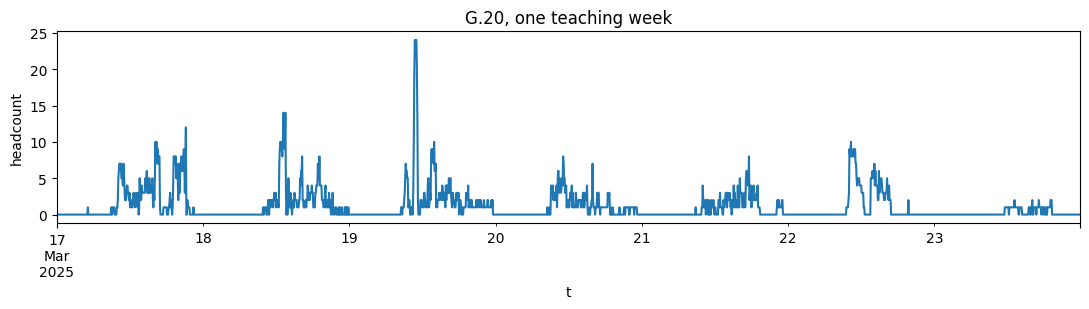

In [5]:
s = series_df["60_G20"]
fig, ax = plt.subplots(figsize=(11, 3.2))
s["2025-03-17":"2025-03-23"].plot(ax=ax)
ax.set_ylabel("headcount"); ax.set_title("G.20, one teaching week")
plt.tight_layout(); plt.show()

###4. Splits, drift and the weekly profile

In [6]:
rows = []
for room in series_df:
    y = series_df[room].to_numpy(); n = len(y)
    tr, te = int(0.6 * n), int(0.8 * n)
    sl = time_slots(series_df.index)
    prof = weekly_profile(y, sl, tr)
    for name, seg in {"train": slice(0, tr), "validation": slice(tr, te), "test": slice(te, n)}.items():
        a = y[seg]
        rows.append({"room": room, "period": name, "start": series_df.index[seg][0].date(),
                     "mean_headcount": np.nanmean(a),
                     "profile_minus_actual": prof[sl[seg]].mean() - np.nanmean(a)})
pd.DataFrame(rows).round(3)

,room,period,start,mean_headcount,profile_minus_actual
0,60_G20,train,2024-03-03,0.948,-0.000
1,60_G20,validation,2025-06-14,0.749,0.196
2,60_G20,test,2025-11-17,0.853,0.096
3,60_G25,train,2024-03-03,0.763,-0.002
4,60_G25,validation,2025-06-14,0.611,0.149
5,60_G25,test,2025-11-17,0.377,0.386


###5. Validation (Tuning, G.20 Only)

tau (bins) -> validation MAE
6 0.815
12 0.7919
24 0.7759
48 0.787
96 0.8288
192 0.8745


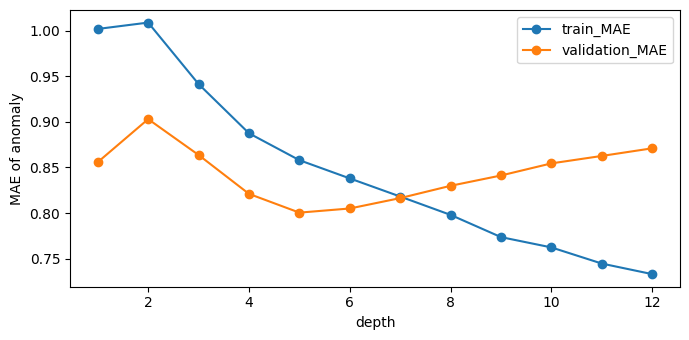

In [7]:
y = series_df["60_G20"].to_numpy(); n = len(y)
train_hi, test_lo = int(0.6 * n), int(0.8 * n)
slots = time_slots(series_df.index)
profile = weekly_profile(y, slots, train_hi)

X_tr, Y_tr = make_training_set(y, slots, profile, 1, train_hi, 4000, seed=11)
X_va, Y_va = make_training_set(y, slots, profile, train_hi, test_lo, 1500, seed=12)

mae = lambda a, b: float(np.abs(a - b).mean())
print("tau (bins) -> validation MAE")
for tau in [6, 12, 24, 48, 96, 192]:
    print(tau, round(mae(Y_va, X_va[:, 7] * np.exp(-X_va[:, 5] / tau)), 4))

curve = []
for d in range(1, 13):
    t = DecisionTreeRegressor(max_depth=d, min_samples_leaf=50, random_state=0).fit(X_tr, Y_tr)
    curve.append({"depth": d, "train_MAE": mae(Y_tr, t.predict(X_tr)),
                  "validation_MAE": mae(Y_va, t.predict(X_va))})
curve = pd.DataFrame(curve)
curve.plot(x="depth", y=["train_MAE", "validation_MAE"], marker="o", figsize=(7, 3.5))
plt.ylabel("MAE of anomaly"); plt.tight_layout(); plt.show()

### NOTE:

###6. Final Test, Both rooms

In [8]:
import os

def run_room(room, n_test, seed=9001):
    s = series_df[room]; y = s.to_numpy(); n = len(y)
    tr, te = int(0.6 * n), int(0.8 * n)
    sl = time_slots(s.index)
    prof = weekly_profile(y, sl, tr)
    Xt, Yt = make_training_set(y, sl, prof, 1, tr, 4000, seed=11)
    models = fit_frozen_models(Xt, Yt)
    st = eligible_starts(y, 288)
    st = st[(st >= te + 1) & (st + 289 <= n)]
    starts = np.random.default_rng(seed).choice(st, size=min(n_test, len(st)), replace=False)
    return score_gaps(y, starts, sl, prof, models)

os.makedirs(DATA + "final", exist_ok=True)
results = {}
for room, n_test in [("60_G20", 2000), ("60_G25", 1000)]:
    path = DATA + f"final/{room}.parquet"
    if os.path.exists(path):
        results[room] = pd.read_parquet(path)
    else:
        results[room] = run_room(room, n_test)
        results[room].to_parquet(path)
    print(room, len(results[room]), "rows")

60_G20 112000 rows
60_G25 56000 rows


###7. Check against earlier G.20 run

In [9]:
old = pd.read_parquet(DATA + "test_results_seed9001.parquet")
m = old.merge(results["60_G20"], on=["gap", "start", "method"], suffixes=("_o", "_n"))
print(len(old), len(m), "| max |MAE diff|:", float(np.abs(m.mae_o - m.mae_n).max()))

112000 112000 | max |MAE diff|: 0.0


###8. Results tables and confidence intervals

In [10]:
for room, res in results.items():
    b = res[res["busy"]]
    print("=====", room)
    print("busy gaps per length:", b[b.method == "linear_interp"].groupby("gap").size().loc[order].tolist())
    for col, title in [("mae", "MAE, busy gaps"), ("bias", "Bias, busy gaps")]:
        print(title); display(b.pivot_table(index="gap", columns="method", values=col).loc[order].round(3))
    print("RMSE, busy gaps")
    display(np.sqrt(b.pivot_table(index="gap", columns="method", values="mse")).loc[order].round(3))

===== 60_G20
busy gaps per length: [622, 688, 785, 926, 1172, 1472, 1676, 1851]
MAE, busy gaps


method,carry_forward,decay_profile,linear_interp,svr_c003,tree_abs_d5,tree_sq_d5,weekly_profile
gap,,,,,,,
15 min,1.260,1.029,1.034,1.520,1.346,1.262,1.827
30 min,1.453,1.135,1.120,1.541,1.393,1.355,1.835
1 h,1.563,1.235,1.230,1.506,1.411,1.428,1.773
2 h,1.626,1.358,1.386,1.432,1.417,1.429,1.661
4 h,1.583,1.227,1.258,1.226,1.218,1.278,1.423
8 h,1.516,1.055,1.177,0.970,0.979,1.084,1.157
12 h,1.525,0.990,1.248,0.882,0.893,1.021,1.048
24 h,1.426,0.931,1.401,0.837,0.829,1.037,0.968


Bias, busy gaps


method,carry_forward,decay_profile,linear_interp,svr_c003,tree_abs_d5,tree_sq_d5,weekly_profile
gap,,,,,,,
15 min,-0.054,-0.025,0.015,-1.100,-0.813,-0.058,-0.847
30 min,-0.120,-0.059,-0.009,-1.034,-0.768,-0.089,-0.744
1 h,-0.183,-0.130,-0.056,-0.970,-0.743,-0.117,-0.642
2 h,-0.180,-0.145,-0.063,-0.816,-0.632,-0.179,-0.458
4 h,-0.135,-0.181,-0.161,-0.671,-0.556,-0.157,-0.254
8 h,-0.029,-0.037,-0.069,-0.512,-0.414,-0.034,-0.052
12 h,-0.018,0.010,0.000,-0.486,-0.375,0.020,-0.011
24 h,-0.002,0.028,0.032,-0.336,-0.340,0.118,0.028


RMSE, busy gaps


...

method,carry_forward,decay_profile,linear_interp,svr_c003,tree_abs_d5,tree_sq_d5,weekly_profile
gap,,,,,,,
15 min,0.549,0.513,0.501,0.618,0.660,0.590,0.842
30 min,0.505,0.489,0.466,0.571,0.575,0.578,0.853
1 h,0.483,0.488,0.447,0.541,0.518,0.577,0.852
2 h,0.477,0.502,0.435,0.505,0.484,0.561,0.825
4 h,0.474,0.552,0.434,0.475,0.451,0.573,0.807
8 h,0.496,0.612,0.443,0.457,0.439,0.588,0.770
12 h,0.503,0.641,0.458,0.448,0.433,0.606,0.750
24 h,0.520,0.678,0.499,0.522,0.437,0.922,0.737


Bias, busy gaps


method,carry_forward,decay_profile,linear_interp,svr_c003,tree_abs_d5,tree_sq_d5,weekly_profile
gap,,,,,,,
15 min,-0.122,-0.089,-0.105,-0.265,-0.454,-0.076,0.123
30 min,-0.063,-0.011,-0.042,-0.143,-0.329,0.038,0.278
1 h,-0.036,0.039,-0.022,-0.076,-0.241,0.111,0.382
2 h,-0.038,0.080,-0.031,-0.075,-0.215,0.124,0.409
4 h,-0.016,0.179,-0.002,-0.062,-0.165,0.184,0.436
8 h,-0.015,0.251,-0.016,-0.074,-0.133,0.207,0.424
12 h,-0.006,0.296,-0.018,-0.067,-0.102,0.239,0.421
24 h,-0.003,0.346,0.000,0.076,-0.084,0.658,0.413


RMSE, busy gaps


method,carry_forward,decay_profile,linear_interp,svr_c003,tree_abs_d5,tree_sq_d5,weekly_profile
gap,,,,,,,
15 min,0.888,0.752,0.768,0.792,0.883,0.750,1.054
30 min,0.867,0.725,0.732,0.779,0.833,0.753,1.098
1 h,0.854,0.730,0.733,0.762,0.794,0.764,1.110
2 h,0.856,0.751,0.748,0.750,0.790,0.766,1.088
4 h,0.857,0.789,0.738,0.719,0.750,0.773,1.071
8 h,0.895,0.874,0.752,0.720,0.749,0.818,1.035
12 h,0.901,0.913,0.781,0.715,0.748,0.858,1.013
24 h,0.918,0.946,0.851,0.798,0.761,1.406,1.003


In [11]:
day_of = {r: series_df.index.strftime("%Y-%m-%d").to_numpy() for r in series_df}
for room, ref in [("60_G20", "decay_profile"), ("60_G25", "linear_interp")]:
    for metric in ["mae", "rmse"]:
        t = compare_to_reference(results[room], day_of[room], ref, order, metric)
        print(room, metric, "vs", ref, "(positive = worse); rows where the interval excludes 0:")
        display(t[t["real"]].round(3))

60_G20 mae vs decay_profile (positive = worse); rows where the interval excludes 0:


,gap,method,n,diff,ci_low,ci_high,real
0,15 min,carry_forward,622,0.231,0.143,0.322,True
2,15 min,svr_c003,622,0.491,0.234,0.832,True
3,15 min,tree_abs_d5,622,0.317,0.152,0.549,True
4,15 min,tree_sq_d5,622,0.233,0.117,0.401,True
5,15 min,weekly_profile,622,0.798,0.523,1.149,True
6,30 min,carry_forward,688,0.318,0.229,0.411,True
8,30 min,svr_c003,688,0.406,0.195,0.690,True
9,30 min,tree_abs_d5,688,0.258,0.115,0.451,True
10,30 min,tree_sq_d5,688,0.221,0.114,0.369,True
11,30 min,weekly_profile,688,0.701,0.474,1.002,True


60_G20 rmse vs decay_profile (positive = worse); rows where the interval excludes 0:


,gap,method,n,diff,ci_low,ci_high,real
0,15 min,carry_forward,622,0.544,0.186,0.897,True
2,15 min,svr_c003,622,1.761,0.531,3.021,True
3,15 min,tree_abs_d5,622,0.914,0.108,1.798,True
4,15 min,tree_sq_d5,622,0.627,0.123,1.241,True
5,15 min,weekly_profile,622,1.942,0.809,3.149,True
6,30 min,carry_forward,688,0.954,0.524,1.447,True
8,30 min,svr_c003,688,1.692,0.554,2.787,True
9,30 min,tree_abs_d5,688,0.972,0.192,1.749,True
10,30 min,tree_sq_d5,688,0.708,0.169,1.261,True
11,30 min,weekly_profile,688,1.855,0.799,2.911,True


60_G25 mae vs linear_interp (positive = worse); rows where the interval excludes 0:


,gap,method,n,diff,ci_low,ci_high,real
0,15 min,carry_forward,446,0.048,0.015,0.081,True
1,15 min,decay_profile,446,0.012,0.007,0.017,True
2,15 min,svr_c003,446,0.116,0.079,0.155,True
3,15 min,tree_abs_d5,446,0.159,0.109,0.210,True
4,15 min,tree_sq_d5,446,0.088,0.061,0.116,True
5,15 min,weekly_profile,446,0.340,0.275,0.407,True
6,30 min,carry_forward,578,0.039,0.013,0.067,True
7,30 min,decay_profile,578,0.023,0.017,0.030,True
8,30 min,svr_c003,578,0.105,0.076,0.135,True
9,30 min,tree_abs_d5,578,0.109,0.073,0.149,True


60_G25 rmse vs linear_interp (positive = worse); rows where the interval excludes 0:


,gap,method,n,diff,ci_low,ci_high,real
0,15 min,carry_forward,446,0.120,0.045,0.186,True
1,15 min,decay_profile,446,-0.016,-0.023,-0.010,True
3,15 min,tree_abs_d5,446,0.115,0.056,0.169,True
5,15 min,weekly_profile,446,0.287,0.191,0.381,True
6,30 min,carry_forward,578,0.136,0.089,0.185,True
8,30 min,svr_c003,578,0.048,0.018,0.080,True
9,30 min,tree_abs_d5,578,0.102,0.069,0.137,True
11,30 min,weekly_profile,578,0.367,0.301,0.436,True
12,1 h,carry_forward,711,0.121,0.086,0.157,True
14,1 h,svr_c003,711,0.029,0.001,0.058,True


###9. Limitations



### Data
1. **Only two rooms could be located.** The occupancy file holds five spaces, but only
   G.20 and G.25 appear in the metadata workbook, whose occupancy sheet is itself
   labelled "Incorrect Data". Results describe these two rooms and may not generalise
   to labs, workshops or meeting rooms.
2. **Environmental data could not be used.** The environmental file holds five sensor
   IDs and none is located in G.20 or G.25, the project was rescoped
   to reconstructing missing headcount from the occupancy record itself.
3. **The record is an event log.** Rows are written only when the count changes, so
   silence is ambiguous. A silence starting in `NotOccupied` is treated as an empty
   room; a silence starting while occupied is treated as unknown after 30 minutes. An
   outage beginning just after a `NotOccupied` event cannot be detected, so the real
   outage counts (21 in G.20, 53 in G.25) are lower bounds.
4. **Short record, rare large events.** The data cover about 25 months. One-off events
   (for example about 30 people in G.20 on 12 March 2026) cannot be predicted by any
   weekly pattern and dominate RMSE.
5. **"Truth" is the sensor itself.** The results measure how well a hidden stretch of
   the recorded headcount can be reconstructed, not agreement with an independent
   count of people.

### Method and validation
6. **Gaps are simulated.** Real outages are rare (under 2 h in G.20, up to about 9.5 h
   in G.25), so errors were measured by hiding known stretches. Real outages may be
   less random; a fault in the shared gateway would remove both rooms at once.
7. **The weekly pattern drifts.** The profile is learned from the first 60% of the
   record. Mean headcount fell afterwards (G.20: 0.948 in training, 0.749 in
   validation, 0.853 in test; G.25: 0.763, 0.611, 0.377). The profile over-predicts the
   test period by 0.096 people in G.20 and 0.386 in G.25, which biases every
   profile-based method upward in G.25 (bias up to +0.35 for the decay rule, 0.12 to
   0.44 for the weekly profile). The profile does not know timetables, holidays or
   semester structure, and was learned from about one cycle of each.
8. **Settings were tuned on G.20 only.** The decay constant (2 hours), tree depth and
   SVR regularisation were chosen on G.20 validation gaps and applied unchanged to
   G.25, so the G.25 comparison tests transfer, not a separately tuned model. The
   decay rule's advantage in G.20 did not replicate in G.25, where plain linear
   interpolation was best or near-best at most gap lengths.
9. **Rankings depend on the metric.** From 8 hours upward in G.20, the SVR and the
   absolute-error tree have the lowest MAE but are biased low (-0.34 to -1.1 people)
   and have higher RMSE than the decay rule. They predict the typical value and
   under-estimate busy periods, which matters for ventilation or energy decisions.
10. **The neural network was not part of the final test.** The MLP (one hidden layer of
    16 neurons) was explored only in the archived notebook and stopped with a
    convergence warning. The SVR was trained on a subsample [state size from
    src/models.py] because its cost grows roughly with the square of the training size.
    Hyperparameter searches were coarse.
11. **The test period was not completely untouched.** The decay rule was designed after
    inspecting test-period gaps during development. Its parameter and all model
    settings were chosen on validation data only, and the final numbers use a fresh
    random sample of gaps (seed 9001), but the results for that rule may be slightly
    optimistic. The test period is about five months (Nov 2025 to Apr 2026) and
    includes the summer closure.
12. **"Busy gap" uses hidden truth.** Splitting gaps by whether they contained
    occupancy cannot be done in a real outage. It was used for diagnosis, and results
    should be read alongside the share of gaps that were busy.
13. **Many comparisons, no correction.** Each room has 96 confidence intervals (6
    methods x 8 gap lengths x 2 metrics), so a few will exclude zero by chance. Day-level
    resampling allows for correlated neighbouring gaps but is approximate. In G.25 the
    differences are small in absolute terms (errors of about 0.4 to 0.6 people), so a
    "real" difference of 0.04 people is not practically important.
14. **Numerical error sources:** 5-minute binning (the state at the start of each bin is
    used), interpolation error inside the gap, and random-sampling error from the
    chosen gaps. Floating-point rounding is negligible. Bin size and gap lengths beyond
    24 hours were not varied. Rerunning the G.20 test reproduced the earlier results
    exactly (maximum MAE difference 0.0), so the pipeline is deterministic.

### Lessons learned
- **Audit the data before choosing the question.** The environmental mapping failure
  forced a re-scope.
- **No single method wins everywhere.** Linear interpolation is the robust choice for
  gaps up to about 2 hours in both rooms. For longer gaps the best method depends on
  the room, the metric and whether the weekly pattern still holds.
- **Simple methods held up.** A one-parameter rule beat trained models in G.20 up to
  4 hours and on RMSE throughout, while plain interpolation was the safest choice in
  G.25. Machine learning gained on MAE only for long gaps and at the cost of bias.
- **Validation periods do not guarantee test performance when usage drifts.** Pairing
  the gaps, resampling by day and replicating in a second room exposed problems a
  single-room validation would have hidden.